# Tuning
Random search over each model's settings (`ratings/tune.py`). A setting is judged by log loss on the last season before the test season; the test season is never touched. The mapping from gap to outcome is fit on the seasons before the validation season (the first season is burn-in).

The best settings are saved in `ratings/best_params.json` and every setting tried in `tuning_log_<gender>.csv`.

In [1]:
%matplotlib inline
import sys, json, pathlib, warnings
warnings.filterwarnings("ignore")
# make the repo root importable no matter which folder the notebook is opened from
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "ratings").is_dir())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from ratings import base
from ratings.data import load_matches
from ratings.tune import PARAMS_PATH, load_best
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

**Re-running the tuning (optional).** Set `RUN_TUNING = True` to search again and overwrite `best_params.json` (takes a long time; needs the database). `ONLY` limits it to some models.

In [2]:
RUN_TUNING = False
ONLY = None            # e.g. ["elo_sqrt", "glicko"]
if RUN_TUNING:
    from ratings.tune import run_tuning
    run_tuning(["male", "female"], n_online=40, n_batch=8, only=ONLY)

## 1. Chosen settings

In [3]:
best = json.loads(PARAMS_PATH.read_text())
for g in best:
    print(g)
    display(pd.DataFrame({m: {**v["params"], "val_log_loss": round(v["val_log_loss"], 4)} for m, v in best[g].items()}).T)

male


,k,hfa,carry,val_log_loss,xg_weight,xg_c,lam,gamma,c,c_week,season_c,rd_max,half_life_days,ridge
elo_none,60.0,70.0,1.0,0.9708,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
elo_sqrt,60.0,70.0,0.9,0.9661,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
elo_wfe_autocorr,40.0,70.0,1.0,0.9663,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
elo_xg,60.0,70.0,1.0,0.9572,0.5,1.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pi,NaN,NaN,0.8,0.9735,NaN,NaN,0.1,0.8,3.0,NaN,NaN,NaN,NaN,NaN
glicko,NaN,60.0,0.9,0.9676,NaN,NaN,NaN,NaN,NaN,2.0,120.0,200.0,NaN,NaN
dixon_coles,NaN,NaN,NaN,0.9692,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,180.0,0.5
dixon_coles_xg,NaN,NaN,NaN,0.9623,0.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,180.0,0.5
ridge_gd,NaN,NaN,NaN,0.9696,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,180.0,2.0
ridge_gd_xg,NaN,NaN,NaN,0.9695,0.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,365.0,2.0


female


,k,hfa,carry,val_log_loss,xg_weight,xg_c,lam,gamma,c,c_week,season_c,rd_max,half_life_days,ridge
elo_none,80.0,50.0,1.00,0.9309,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
elo_sqrt,80.0,70.0,1.00,0.9238,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
elo_wfe_autocorr,60.0,50.0,1.00,0.9252,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
elo_xg,60.0,30.0,0.90,0.9135,0.25,0.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pi,NaN,NaN,0.95,0.9259,NaN,NaN,0.1,0.5,5.0,NaN,NaN,NaN,NaN,NaN
glicko,NaN,40.0,0.90,0.9216,NaN,NaN,NaN,NaN,NaN,2.0,120.0,300.0,NaN,NaN
dixon_coles,NaN,NaN,NaN,0.9139,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,365.0,0.5
dixon_coles_xg,NaN,NaN,NaN,0.9059,0.50,NaN,NaN,NaN,NaN,NaN,NaN,NaN,180.0,0.5
ridge_gd,NaN,NaN,NaN,0.9192,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,365.0,2.0
ridge_gd_xg,NaN,NaN,NaN,0.9104,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,365.0,2.0


## 2. Everything that was tried
The saved log has one row per setting tried. Here, for each model, how much the validation log loss varies across settings: a model whose best and median settings are far apart is sensitive to tuning.

In [4]:
logs = pd.concat([pd.read_csv(ROOT / "ratings" / f"tuning_log_{g}.csv") for g in ("male", "female")])
spread = logs.groupby(["gender", "model"])["val_log_loss"].agg(best="min", median="median", worst="max", tried="size").round(4)
display(spread)

best  median   worst  tried
gender model                                          
female elo_none          0.9309  0.9544  1.0246     60
       elo_sqrt          0.9238  0.9417  0.9952     60
       elo_wfe_autocorr  0.9252  0.9434  1.0093     60
       elo_xg            0.9135  0.9477  1.0301     60
male   elo_none          0.9708  0.9802  1.0220     60
       elo_sqrt          0.9661  0.9733  1.0031     60
       elo_wfe_autocorr  0.9663  0.9750  1.0115     60
       elo_xg            0.9572  0.9772  1.0299     60

### Effect of the main Elo settings (men, `elo_sqrt`)

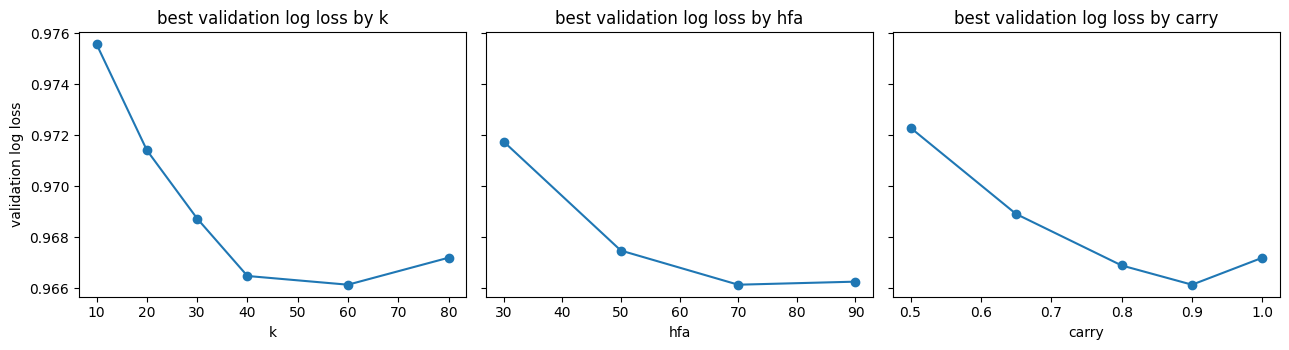

In [5]:
e = logs[(logs.gender == "male") & (logs.model == "elo_sqrt")]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, col in zip(axes, ["k", "hfa", "carry"]):
    s = e.groupby(col)["val_log_loss"].min()
    ax.plot(s.index, s.values, marker="o")
    ax.set_xlabel(col); ax.set_title(f"best validation log loss by {col}")
axes[0].set_ylabel("validation log loss")
plt.tight_layout(); plt.show()